# CS-6600 Project Part 2: NameThatLLM

Weber State University

Team GuessGPT: Jeffery Hatch, Fred Walter, Isaac Christensen, Zachary Saylors

Can the nine writing-style features from Part 1 identify which LLM wrote a paragraph on an unseen prompt? We start with a shared split and two baselines.

Use the same Python kernel as Part 1 and run all cells. If you need to set up a fresh environment, see the optional install command in the [README](README.md).

## Data

We use 2,699 paragraphs from 18 LLMs across 150 prompts from Kaggle's [Name That LLM competition](https://www.kaggle.com/competitions/name-that-llm). Part 1 found differences in passage length and punctuation, which motivated the features we use here.

We trim whitespace and remove passages without letters or numbers. We keep case, punctuation, and valid outliers.

In [1]:
import re
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from nltk.tokenize import sent_tokenize
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

data_path = Path('dataset/data.csv')
data_url = 'https://raw.githubusercontent.com/FredWltr/NameThatLLM/3f44e3197c7b9af1c46eefee8d5fcfeb357be687/dataset/data.csv'
data = pd.read_csv(data_path if data_path.exists() else data_url, dtype='string')
original_count = len(data)
data['text'] = data['text'].fillna('').str.strip()
data = data.loc[data['text'].str.contains(r'[^\W_]', na=False)].reset_index(drop=True)
assert not data[['id', 'prompt_id', 'model']].isna().any().any()
assert data['id'].is_unique and data['text'].is_unique
print(f'Kept {len(data):,} passages; removed {original_count - len(data):,}.')
print(f"{data['model'].nunique()} labels and {data['prompt_id'].nunique()} prompts.")

Kept 2,699 passages; removed 0.
18 labels and 150 prompts.


## Shared splits

Use the Part 1 split: 80% of prompts for training and 20% for the final test. Split the training prompts into three validation folds. The CSV fixes the same assignments for every teammate, even if their data is sorted differently. Join on `id` and use `validation_fold` to select validation rows within training.

In [2]:
manifest_path = Path('dataset/part2_split.csv')
manifest_types = {'id': 'string', 'prompt_id': 'string', 'split': 'string', 'validation_fold': 'Int64'}

if manifest_path.exists():
    manifest = pd.read_csv(manifest_path, dtype=manifest_types)
else:
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    train_idx, _ = next(splitter.split(data, data['model'], data['prompt_id']))
    manifest = data[['id', 'prompt_id']].copy()
    manifest['split'] = 'test'
    manifest.loc[train_idx, 'split'] = 'train'
    manifest['validation_fold'] = pd.Series(pd.NA, index=data.index, dtype='Int64')

    training = data.iloc[train_idx]
    cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=6600)
    for fold, (_, val_idx) in enumerate(cv.split(training, training['model'], training['prompt_id']), start=1):
        manifest.loc[train_idx[val_idx], 'validation_fold'] = fold

    manifest_path.parent.mkdir(parents=True, exist_ok=True)
    manifest.to_csv(manifest_path, index=False)

rows = data.merge(manifest, on=['id', 'prompt_id'], how='outer', validate='one_to_one', indicator=True)
assert rows['_merge'].eq('both').all(), 'Split file does not match the dataset.'
assert set(rows['split']) == {'train', 'test'}
assert rows.groupby('prompt_id')['split'].nunique().eq(1).all(), 'A prompt crosses train and test.'

train_rows = rows.loc[rows['split'].eq('train')].reset_index(drop=True)
test_rows = rows.loc[rows['split'].eq('test')].reset_index(drop=True)
assert test_rows['validation_fold'].isna().all()
assert train_rows['validation_fold'].notna().all()
assert set(train_rows['validation_fold']) == {1, 2, 3}
assert train_rows.groupby('prompt_id')['validation_fold'].nunique().eq(1).all(), 'A prompt crosses validation folds.'
labels = set(rows['model'])
assert set(train_rows['model']) == set(test_rows['model']) == labels

folds = []
for fold in (1, 2, 3):
    is_validation = train_rows['validation_fold'].eq(fold).to_numpy(dtype=bool)
    fit_idx = np.flatnonzero(~is_validation)
    val_idx = np.flatnonzero(is_validation)
    assert set(train_rows.iloc[fit_idx]['model']) == set(train_rows.iloc[val_idx]['model']) == labels
    folds.append((fit_idx, val_idx))

display(rows.groupby('split').agg(paragraphs=('id', 'size'), prompts=('prompt_id', 'nunique')))
display(train_rows.groupby('validation_fold').agg(paragraphs=('id', 'size'), prompts=('prompt_id', 'nunique')))

,paragraphs,prompts
split,,
test,540,30
train,2159,120


,paragraphs,prompts
validation_fold,,
1,719,40
2,720,40
3,720,40


## Features

These are the nine Part 1 features: length, sentence structure, and punctuation rates. Only text is used to compute them. Raw text stays available in `train_rows` for models that use it directly.

In [3]:
FEATURE_COLUMNS = [
    "word_count",
    "avg_word_length",
    "avg_sentence_length",
    "punctuation_per_100_words",
    "comma_per_100_words",
    "semicolon_per_100_words",
    "em_dash_per_100_words",
    "straight_apostrophe_per_100_words",
    "curly_apostrophe_per_100_words",
]


def extract_style_features(text):
    """Calculate nine numerical writing-style features for one passage."""
    words = text.split()
    word_count = len(words)

    letter_words = re.findall(r"\b[A-Za-z]+\b", text)
    avg_word_length = (
        sum(map(len, letter_words)) / len(letter_words)
        if letter_words else 0
    )

    sentences = sent_tokenize(text)
    avg_sentence_length = (
        sum(len(sentence.split()) for sentence in sentences) / len(sentences)
        if sentences else 0
    )

    punctuation_count = sum(
        unicodedata.category(char).startswith("P") for char in text
    )

    def rate(characters):
        return sum(text.count(char) for char in characters) / word_count * 100

    return {
        "word_count": word_count,
        "avg_word_length": avg_word_length,
        "avg_sentence_length": avg_sentence_length,
        "punctuation_per_100_words": punctuation_count / word_count * 100,
        "comma_per_100_words": rate(","),
        "semicolon_per_100_words": rate(";"),
        "em_dash_per_100_words": rate("—"),
        "straight_apostrophe_per_100_words": rate("'"),
        "curly_apostrophe_per_100_words": rate("’"),
    }

try:
    nltk.data.find('tokenizers/punkt_tab/english/')
except LookupError:
    if not nltk.download('punkt_tab', quiet=True):
        raise RuntimeError('Install the NLTK punkt_tab resource before running this cell.')

X = pd.DataFrame(train_rows['text'].map(extract_style_features).tolist(), columns=FEATURE_COLUMNS)
y = train_rows['model'].astype(str)
assert len(X) == len(y) and np.isfinite(X.to_numpy()).all()
display(X.head())

,word_count,avg_word_length,avg_sentence_length,punctuation_per_100_words,comma_per_100_words,semicolon_per_100_words,em_dash_per_100_words,straight_apostrophe_per_100_words,curly_apostrophe_per_100_words
0,192,4.782383,24.000000,15.104167,8.854167,1.041667,0.000000,0.0,0.520833
1,77,5.012987,19.250000,15.584416,10.389610,0.000000,0.000000,0.0,0.000000
2,97,4.343434,24.250000,15.463918,8.247423,0.000000,2.061856,0.0,0.000000
3,73,5.082192,18.250000,12.328767,6.849315,0.000000,0.000000,0.0,0.000000
4,58,6.152542,19.333333,17.241379,10.344828,0.000000,0.000000,0.0,1.724138


## Baselines

The dummy model always picks the most common label in its training fold. Logistic regression uses the nine features, with scaling fitted inside each fold. Both use the same folds. Balanced accuracy averages recall across labels; macro F1 gives each label equal weight.

In [4]:
models = {
    'Most frequent': DummyClassifier(strategy='most_frequent'),
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000)),
}

records = []
validation_predictions = pd.Series(index=y.index, dtype=object)
for name, model in models.items():
    for fold, (fit_idx, val_idx) in enumerate(folds, start=1):
        fitted_model = clone(model).fit(X.iloc[fit_idx], y.iloc[fit_idx])
        actual = y.iloc[val_idx]
        predicted = fitted_model.predict(X.iloc[val_idx])
        records.append({
            'model': name,
            'fold': fold,
            'balanced_accuracy': balanced_accuracy_score(actual, predicted),
            'macro_f1': f1_score(actual, predicted, average='macro', zero_division=0),
        })
        if name == 'Logistic regression':
            validation_predictions.iloc[val_idx] = predicted

assert validation_predictions.notna().all()
results = pd.DataFrame(records)
mean_scores = results.groupby('model', sort=False)[['balanced_accuracy', 'macro_f1']].mean()
display(results.round(4))

,model,fold,balanced_accuracy,macro_f1
0,Most frequent,1,0.0556,0.0057
1,Most frequent,2,0.0556,0.0058
2,Most frequent,3,0.0556,0.0058
3,Logistic regression,1,0.2694,0.2426
4,Logistic regression,2,0.2597,0.2405
5,Logistic regression,3,0.2486,0.2302


## Validation results

The bars show mean scores across the three validation folds. In the heatmap, each row shows what the model predicted for one actual LLM. The diagonal shows correct predictions. Off the diagonal, only mix-ups that account for at least 10% of that row are labeled.

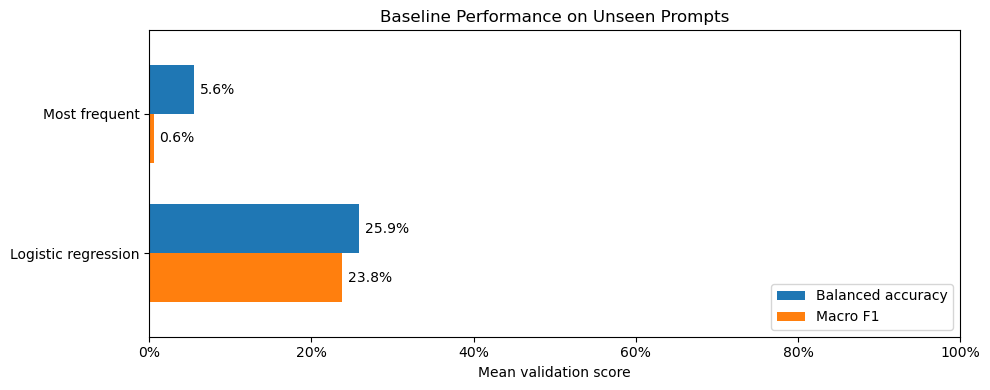

In [5]:
score_plot = mean_scores.rename(columns={
    'balanced_accuracy': 'Balanced accuracy',
    'macro_f1': 'Macro F1',
}).mul(100)

ax = score_plot.plot.barh(figsize=(10, 4), width=0.7)
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.1f%%', padding=4)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_xlim(0, 100)
ax.set_xlabel('Mean validation score')
ax.set_ylabel('')
ax.legend(loc='lower right')
plt.title('Baseline Performance on Unseen Prompts')
plt.tight_layout()
plt.show()

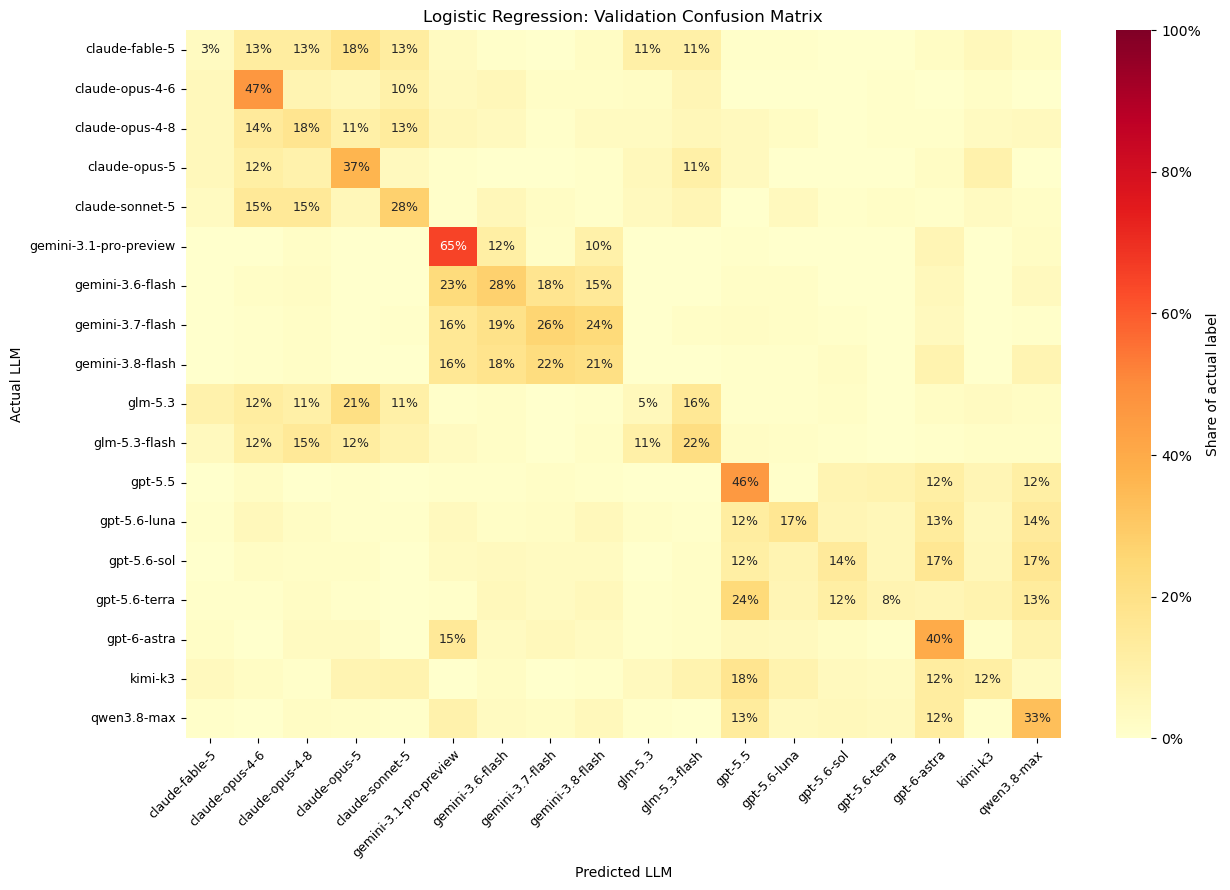

In [6]:
# Each prediction comes from the fold where its prompt was held out.
model_labels = sorted(y.unique())
confusion = confusion_matrix(y, validation_predictions, labels=model_labels, normalize='true')
annotations = [
    [f'{share:.0%}' if i == j or share >= 0.10 else '' for j, share in enumerate(row)]
    for i, row in enumerate(confusion)
]

plt.figure(figsize=(13, 9))
ax = sns.heatmap(
    confusion, annot=annotations, fmt='', cmap='YlOrRd', vmin=0, vmax=1,
    xticklabels=model_labels, yticklabels=model_labels,
    annot_kws={'size': 9},
    cbar_kws={'label': 'Share of actual label', 'format': PercentFormatter(xmax=1)},
)
ax.tick_params(axis='both', labelsize=9)
plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')
plt.title('Logistic Regression: Validation Confusion Matrix')
plt.xlabel('Predicted LLM')
plt.ylabel('Actual LLM')
plt.tight_layout()
plt.show()

Logistic regression averaged 25.9% balanced accuracy and 23.8% macro F1. It beat the dummy baseline but still mixed up many LLMs. For example, it labeled 22% of Gemini 3.8 Flash passages as Gemini 3.7 Flash.

## Next steps

Use the same folds and metrics to compare other models. Fit preprocessing on each fold's training rows. Choose the model from validation scores, fit it on all training rows, then evaluate it on the test prompts. Part 1 used the full dataset for EDA, so note that limitation in the final report.

### Multi Layer Perceptron

In [7]:
# pip install --upgrade keras torch torchvision
import os
os.environ["KERAS_BACKEND"] = "torch"

import keras
from sklearn.metrics import balanced_accuracy_score, f1_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

In [8]:
# Map of each model to its company
model_to_company = {
    # Alibaba
    "qwen3.8-max": "Alibaba",

    # Google
    "gemini-3.6-flash": "Google",
    "gemini-3.1-pro-preview": "Google",
    "gemini-3.8-flash": "Google",
    "gemini-3.7-flash": "Google",

    # Zhipu AI
    "glm-5.3-flash": "Zhipu AI",
    "glm-5.3": "Zhipu AI",

    # OpenAI
    "gpt-5.6-luna": "OpenAI",
    "gpt-5.6-terra": "OpenAI",
    "gpt-5.5": "OpenAI",
    "gpt-6-astra": "OpenAI",
    "gpt-5.6-sol": "OpenAI",

    # Anthropic
    "claude-sonnet-5": "Anthropic",
    "claude-opus-4-8": "Anthropic",
    "claude-opus-4-6": "Anthropic",
    "claude-fable-5": "Anthropic",
    "claude-opus-5": "Anthropic",

    # Moonshot AI
    "kimi-k3": "Moonshot AI"
}

In [9]:
# Derive the company value from the model
y_model = pd.Series(y).astype(str)
y_company = y_model.map(model_to_company)

In [10]:
# Neural Network requires labels to be numeric values (encoded). In this case, "company" and "model" must have different encoders.
company_encoder = LabelEncoder()
model_encoder = LabelEncoder()

y_company_encoded = pd.Series(company_encoder.fit_transform(y_company), name="company")

y_model_encoded = pd.Series(model_encoder.fit_transform(y_model), name="model")

n_companies = len(company_encoder.classes_)
n_models = len(model_encoder.classes_)

In [11]:
# Simple Multi Layer Perceptron with a couple of hidden layers. It also include a dropout to limit overfitting
def build_mlp():

    mlp = keras.models.Sequential([
        keras.layers.Input(shape=(X.shape[1],), name="features"),

        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dense(16, activation="relu"),

        keras.layers.Dropout(0.2),

        keras.layers.Dense(y_model_encoded.nunique(), activation="softmax")
    ])

    mlp.compile(
        loss="sparse_categorical_crossentropy", 
        # optimizer="sgd", 
        optimizer="adam",
        metrics=["accuracy"]
    )

    return mlp


========== Fold 1 ==========


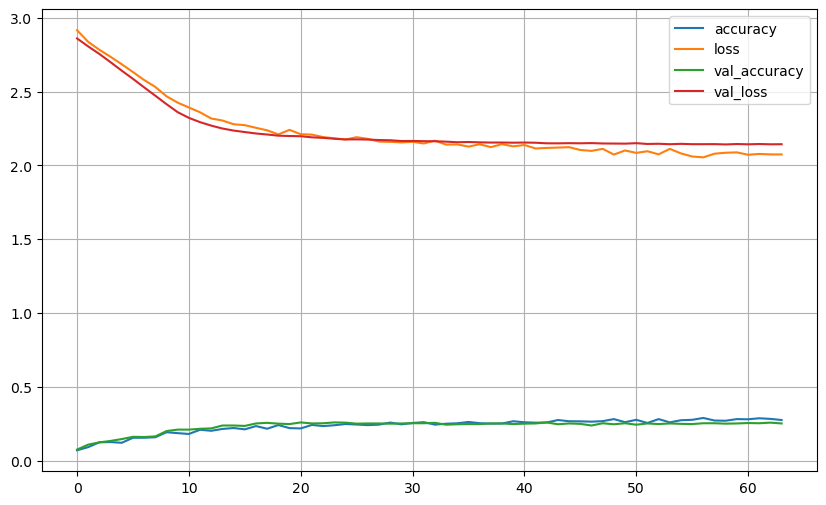

Validation accuracy: 0.2517
Balanced accuracy: 0.2514
Macro F1: 0.2279

========== Fold 2 ==========


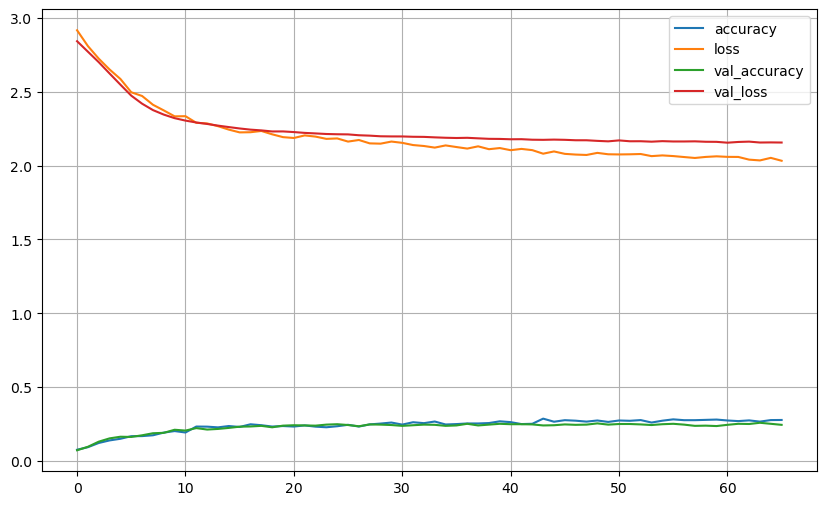

Validation accuracy: 0.2458
Balanced accuracy: 0.2458
Macro F1: 0.2289

========== Fold 3 ==========


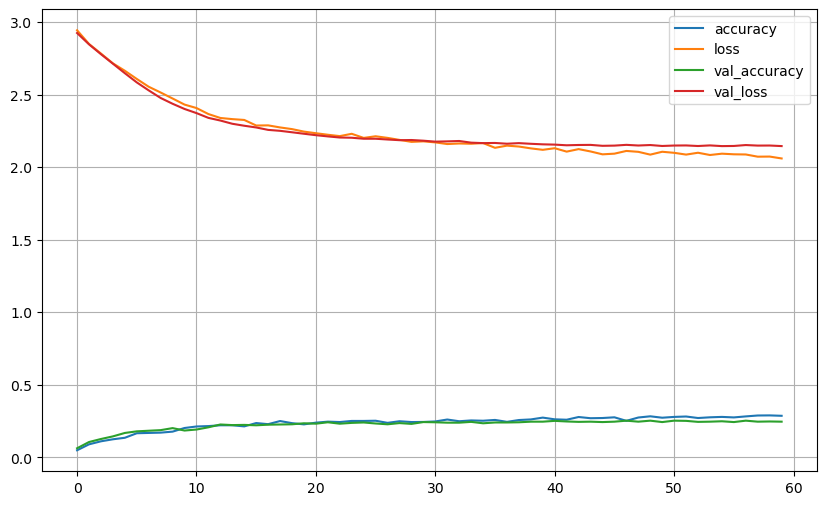

Validation accuracy: 0.2486
Balanced accuracy: 0.2486
Macro F1: 0.2215


In [12]:
# Train the regular MLP on each fold.
mlp_fold_results = []

for fold, (fit_idx, val_idx) in enumerate(folds, start=1):
    keras.backend.clear_session()
    keras.utils.set_random_seed(6600 + fold)

    print(f"\n========== Fold {fold} ==========")

    scaler = StandardScaler()

    X_train_fold = scaler.fit_transform(X.iloc[fit_idx])
    y_train_fold = y_model_encoded.iloc[fit_idx].values.ravel()

    X_val_fold = scaler.transform(X.iloc[val_idx])
    y_val_fold = y_model_encoded.iloc[val_idx].values.ravel()

    mlp = build_mlp()

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )

    history = mlp.fit(
        X_train_fold,
        y_train_fold,
        epochs=100,
        batch_size=32,
        validation_data=(X_val_fold, y_val_fold),
        callbacks=[early_stopping],
        verbose=0
    )

    pd.DataFrame(history.history).plot(figsize=(10, 6))
    plt.grid(True)
    plt.show()

    val_loss, val_accuracy = mlp.evaluate(
        X_val_fold,
        y_val_fold,
        verbose=0
    )

    probabilities = mlp.predict(X_val_fold, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)

    balanced_accuracy = balanced_accuracy_score(y_val_fold, y_pred)
    macro_f1 = f1_score(
        y_val_fold,
        y_pred,
        average="macro",
        zero_division=0
    )

    mlp_fold_results.append({
        "fold": fold,
        "seed": 6600 + fold,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "balanced_accuracy": balanced_accuracy,
        "macro_f1": macro_f1
    })

    print(f"Validation accuracy: {val_accuracy:.4f}")
    print(f"Balanced accuracy: {balanced_accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")

In [13]:
# Both outputs are learned jointly.
# The LLM prediction uses the original features and predicted company probabilities.
def build_hierarchical_mlp(n_features, n_companies, n_models):

    inputs = keras.Input(shape=(n_features,))
    x = keras.layers.Dense(32, activation="relu")(inputs)
    x = keras.layers.Dropout(0.2)(x)
    x = keras.layers.Dense(16, activation="relu")(x)

    # Company classification
    company_output = keras.layers.Dense(
        n_companies,
        activation="softmax",
        name="company"
    )(x)

    # Original features + company probabilities
    combined = keras.layers.Concatenate()([
        inputs,
        company_output
    ])

    # Model classification
    z = keras.layers.Dense(16, activation="relu")(combined)
    z = keras.layers.Dropout(0.2)(z)
    model_output = keras.layers.Dense(
        n_models,
        activation="softmax",
        name="model"
    )(z)

    mlp = keras.Model(
        inputs=inputs,
        outputs={
            "company": company_output,
            "model": model_output
        }
    )

    mlp.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),

        loss={
            "company": "sparse_categorical_crossentropy",
            "model": "sparse_categorical_crossentropy"
        },

        loss_weights={
            "company": 0.5,
            "model": 1.0
        },

        metrics={
            "company": ["accuracy"],
            "model": ["accuracy"]
        }
    )

    return mlp

In [14]:
from sklearn.utils.class_weight import compute_class_weight

# Each company has a different amount of models resulting in a unbalance dataset regarding the "company" label. In this case, using weight limit this impact.

def get_company_sample_weights(y_company):

    classes = np.unique(y_company)

    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y_company
    )

    weight_map = dict(zip(classes, weights))

    sample_weights = np.array([
        weight_map[label] for label in y_company
    ])

    return sample_weights


========== Fold 1 ==========


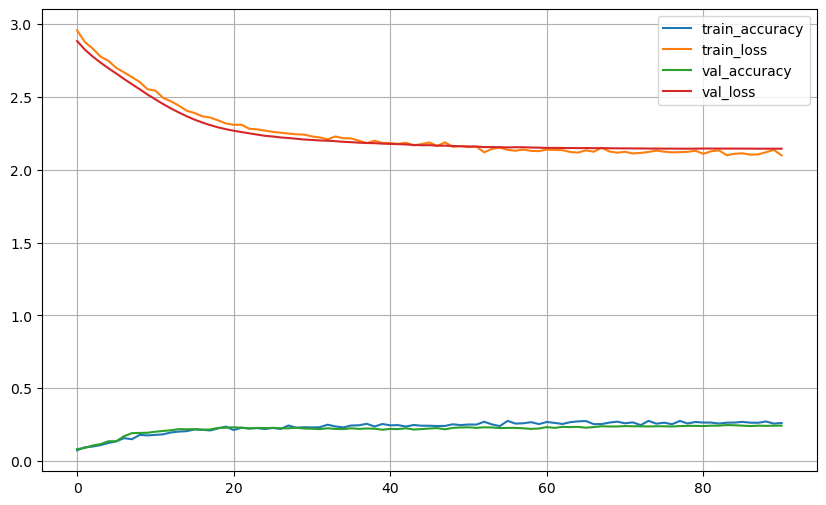

Company accuracy: 0.4910
Model accuracy: 0.2406
Balanced accuracy: 0.2403
Macro F1: 0.2076

========== Fold 2 ==========


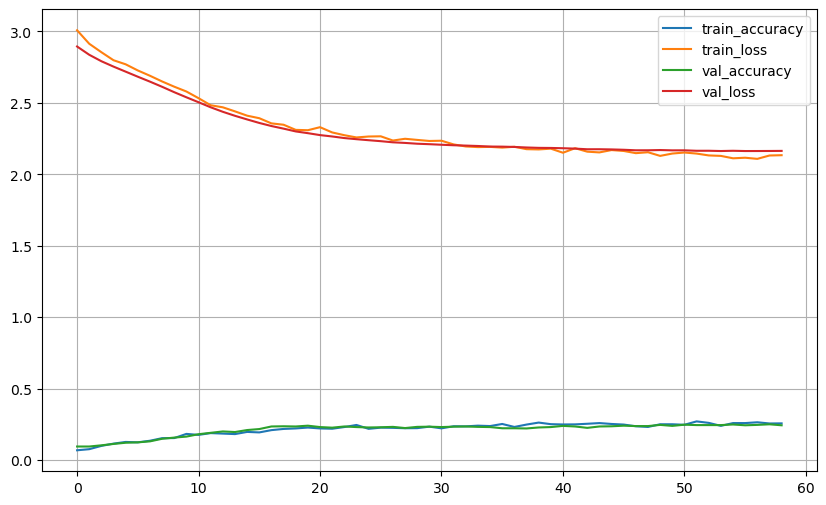

Company accuracy: 0.5125
Model accuracy: 0.2375
Balanced accuracy: 0.2375
Macro F1: 0.2150

========== Fold 3 ==========


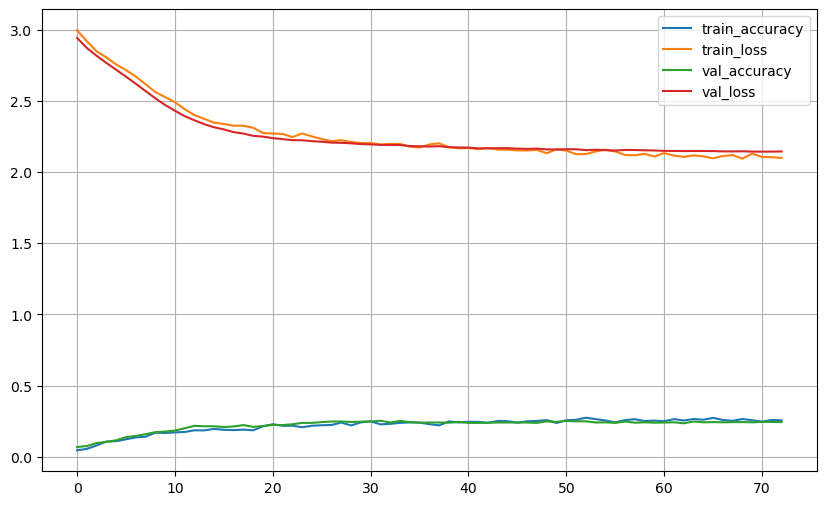

Company accuracy: 0.5069
Model accuracy: 0.2403
Balanced accuracy: 0.2403
Macro F1: 0.2102


In [16]:
company_mlp_fold_results = []

for fold, (fit_idx, val_idx) in enumerate(folds, start=1):
    keras.backend.clear_session()
    keras.utils.set_random_seed(6600 + fold)

    print(f"\n========== Fold {fold} ==========")

    scaler = StandardScaler()

    X_train_fold = scaler.fit_transform(X.iloc[fit_idx])
    y_train_fold = {
        "company": y_company_encoded.iloc[fit_idx].values,
        "model": y_model_encoded.iloc[fit_idx].values
    }

    X_val_fold = scaler.transform(X.iloc[val_idx])
    y_val_fold = {
        "company": y_company_encoded.iloc[val_idx].values,
        "model": y_model_encoded.iloc[val_idx].values
    }

    sample_weights = {
        "company": get_company_sample_weights(y_train_fold["company"]),
        "model": np.ones(len(y_train_fold["model"]))
    }

    mlp = build_hierarchical_mlp(
        n_features=X.shape[1],
        n_companies=n_companies,
        n_models=n_models
    )

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True
    )

    reduce_lr = keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=0.00001
    )

    history = mlp.fit(
        X_train_fold,
        y_train_fold,
        sample_weight=sample_weights,
        epochs=100,
        batch_size=32,
        validation_data=(X_val_fold, y_val_fold),
        callbacks=[early_stopping, reduce_lr],
        verbose=0
    )

    metrics = pd.DataFrame({
        "train_accuracy": history.history["model_accuracy"],
        "train_loss": history.history["model_loss"],
        "val_accuracy": history.history["val_model_accuracy"],
        "val_loss": history.history["val_model_loss"]
    })
    metrics.plot(figsize=(10, 6))
    plt.grid(True)
    plt.show()

    evaluation = mlp.evaluate(
        X_val_fold,
        y_val_fold,
        return_dict=True,
        verbose=0
    )

    predictions = mlp.predict(X_val_fold, verbose=0)
    y_pred = np.argmax(predictions["model"], axis=1)

    balanced_accuracy = balanced_accuracy_score(
        y_val_fold["model"],
        y_pred
    )

    macro_f1 = f1_score(
        y_val_fold["model"],
        y_pred,
        average="macro",
        zero_division=0
    )

    company_mlp_fold_results.append({
        "fold": fold,
        "seed": 6600 + fold,
        "val_loss": evaluation["loss"],
        "company_accuracy": evaluation["company_accuracy"],
        "model_accuracy": evaluation["model_accuracy"],
        "balanced_accuracy": balanced_accuracy,
        "macro_f1": macro_f1
    })

    print(f"Company accuracy: {evaluation['company_accuracy']:.4f}")
    print(f"Model accuracy: {evaluation['model_accuracy']:.4f}")
    print(f"Balanced accuracy: {balanced_accuracy:.4f}")
    print(f"Macro F1: {macro_f1:.4f}")

In [17]:
comparison_results = pd.concat(
    [
        results[["model", "fold", "balanced_accuracy", "macro_f1"]],
        pd.DataFrame(mlp_fold_results).assign(model="MLP"),
        pd.DataFrame(company_mlp_fold_results).assign(
            model="Company-guided MLP"
        )
    ],
    ignore_index=True
)

summary = (
    comparison_results
    .groupby("model", sort=False)[["balanced_accuracy", "macro_f1"]]
    .agg(["mean", "std"])
)

print("Validation means and standard deviations, shown as percentages:")
display(summary.mul(100).round(1))

Validation means and standard deviations, shown as percentages:


balanced_accuracy      macro_f1     
                                 mean  std     mean  std
model                                                   
Most frequent                     5.6  0.0      0.6  0.0
Logistic regression              25.9  1.0     23.8  0.7
MLP                              24.9  0.3     22.6  0.4
Company-guided MLP               23.9  0.2     21.1  0.4

## Feature comparisons

Do additional writing features improve classification? We keep logistic regression and the same three validation folds, changing only the features.

We compare length, punctuation, the original nine features, and expanded features with and without common function words. The new features include sentence variation, vocabulary diversity, capitalization, and additional punctuation rates.

Scaling is fitted inside each training fold. These comparisons use validation data, with the final test reserved for later.

In [18]:
from collections import Counter

EXTRA_PUNCTUATION = {
    "period": ".",
    "colon": ":",
    "exclamation": "!",
    "question": "?",
    "hyphen": "-",
    "en_dash": "\u2013",
    "parentheses": "()",
    "brackets": "[]",
    "double_quotes": '"',
    "curly_double_quotes": "\u201c\u201d",
    "slash": "/",
    "backslash": "\\",
    "asterisk": "*",
    "underscore": "_",
    "backtick": "`",
}

FUNCTION_WORDS = (
    "the", "a", "an", "and", "or", "but", "if", "because",
    "while", "although", "of", "to", "in", "on", "for", "with",
    "by", "from", "as", "that", "this", "it", "is", "are", "be",
    "can", "may", "we", "you", "i",
)


def extract_extra_style_features(text):
    word_count = max(len(text.split()), 1)
    letter_words = re.findall(r"\b[A-Za-z]+\b", text.lower())
    word_counts = Counter(letter_words)
    word_lengths = [len(word) for word in letter_words]
    sentence_lengths = [
        len(sentence.split()) for sentence in sent_tokenize(text)
    ]
    letters = [char for char in text if char.isalpha()]

    features = {}
    for name, characters in EXTRA_PUNCTUATION.items():
        features[f"{name}_per_100_words"] = (
            sum(text.count(char) for char in characters) / word_count * 100
        )

    features.update({
        "sentence_count": len(sentence_lengths),
        "sentence_length_std": (
            float(np.std(sentence_lengths)) if sentence_lengths else 0.0
        ),
        "word_length_std": (
            float(np.std(word_lengths)) if word_lengths else 0.0
        ),
        "unique_word_fraction": (
            len(word_counts) / max(len(letter_words), 1)
        ),
        "single_use_word_fraction": (
            sum(count == 1 for count in word_counts.values())
            / max(len(letter_words), 1)
        ),
        "uppercase_fraction": (
            sum(char.isupper() for char in letters) / max(len(letters), 1)
        ),
        "digits_per_100_words": (
            sum(char.isdigit() for char in text) / word_count * 100
        ),
        "symbols_per_100_words": (
            sum(unicodedata.category(char).startswith("S") for char in text)
            / word_count * 100
        ),
        "newlines_per_100_words": text.count("\n") / word_count * 100,
    })

    for word in FUNCTION_WORDS:
        features[f"function_{word}_per_100_words"] = (
            word_counts[word] / word_count * 100
        )

    return features


assert X.index.equals(train_rows.index) and y.index.equals(train_rows.index)

extra_style_features = pd.DataFrame(
    train_rows["text"].map(extract_extra_style_features).tolist(),
    index=X.index,
)
X_expanded = pd.concat([X, extra_style_features], axis=1)

assert X_expanded.columns.is_unique
assert np.isfinite(X_expanded.to_numpy()).all()

print(f"Original features: {X.shape[1]}")
print(f"Expanded features: {X_expanded.shape[1]}")
display(X_expanded.head())

Original features: 9
Expanded features: 63


,word_count,avg_word_length,avg_sentence_length,punctuation_per_100_words,comma_per_100_words,semicolon_per_100_words,em_dash_per_100_words,straight_apostrophe_per_100_words,curly_apostrophe_per_100_words,period_per_100_words,...,function_this_per_100_words,function_it_per_100_words,function_is_per_100_words,function_are_per_100_words,function_be_per_100_words,function_can_per_100_words,function_may_per_100_words,function_we_per_100_words,function_you_per_100_words,function_i_per_100_words
0,192,4.782383,24.000000,15.104167,8.854167,1.041667,0.000000,0.0,0.520833,4.166667,...,0.000000,1.041667,2.604167,1.041667,0.000000,1.562500,0.0,1.041667,0.000000,0.0
1,77,5.012987,19.250000,15.584416,10.389610,0.000000,0.000000,0.0,0.000000,5.194805,...,0.000000,0.000000,0.000000,0.000000,1.298701,0.000000,0.0,0.000000,0.000000,0.0
2,97,4.343434,24.250000,15.463918,8.247423,0.000000,2.061856,0.0,0.000000,4.123711,...,0.000000,3.092784,1.030928,0.000000,0.000000,0.000000,0.0,0.000000,3.092784,0.0
3,73,5.082192,18.250000,12.328767,6.849315,0.000000,0.000000,0.0,0.000000,5.479452,...,1.369863,1.369863,1.369863,0.000000,0.000000,1.369863,0.0,5.479452,0.000000,0.0
4,58,6.152542,19.333333,17.241379,10.344828,0.000000,0.000000,0.0,1.724138,5.172414,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0


In [19]:
feature_sets = {
    "Word count (1)": X[["word_count"]],
    "Length (3)": X[[
        "word_count",
        "avg_word_length",
        "avg_sentence_length",
    ]],
    "Punctuation (6)": X[[
        "punctuation_per_100_words",
        "comma_per_100_words",
        "semicolon_per_100_words",
        "em_dash_per_100_words",
        "straight_apostrophe_per_100_words",
        "curly_apostrophe_per_100_words",
    ]],
    "Original (9)": X,
    "Expanded without function words (33)": X_expanded.loc[
        :, ~X_expanded.columns.str.startswith("function_")
    ],
    "Expanded (63)": X_expanded,
}

feature_records = []
feature_predictions = pd.DataFrame(
    index=y.index, columns=list(feature_sets), dtype=object
)

for name, inputs in feature_sets.items():
    for fold, (fit_idx, val_idx) in enumerate(folds, start=1):
        fit_prompts = set(train_rows.iloc[fit_idx]["prompt_id"])
        val_prompts = set(train_rows.iloc[val_idx]["prompt_id"])
        assert fit_prompts.isdisjoint(val_prompts)

        feature_model = make_pipeline(
            StandardScaler(),
            LogisticRegression(C=1.0, max_iter=3000),
        )
        feature_model.fit(inputs.iloc[fit_idx], y.iloc[fit_idx])
        predicted = feature_model.predict(inputs.iloc[val_idx])
        actual = y.iloc[val_idx]

        feature_records.append({
            "features": name,
            "fold": fold,
            "balanced_accuracy": balanced_accuracy_score(actual, predicted),
            "macro_f1": f1_score(
                actual, predicted, average="macro", zero_division=0
            ),
        })
        feature_predictions.loc[y.index[val_idx], name] = predicted

    print(f"Finished: {name}")

assert feature_predictions.notna().all().all()

feature_comparison_results = pd.DataFrame(feature_records)

feature_summary = (
    feature_comparison_results
    .groupby("features", sort=False)[["balanced_accuracy", "macro_f1"]]
    .agg(["mean", "std"])
)

feature_mean_scores = (
    feature_comparison_results
    .groupby("features", sort=False)[["balanced_accuracy", "macro_f1"]]
    .mean()
)

print("Validation means and standard deviations, as percentages:")
display(feature_summary.mul(100).round(1))

Finished: Word count (1)
Finished: Length (3)
Finished: Punctuation (6)
Finished: Original (9)
Finished: Expanded without function words (33)
Finished: Expanded (63)
Validation means and standard deviations, as percentages:


balanced_accuracy      macro_f1     
                                                  mean  std     mean  std
features                                                                 
Word count (1)                                     6.2  0.4      2.4  1.1
Length (3)                                        12.4  0.5      9.4  0.8
Punctuation (6)                                   20.0  1.1     17.2  0.6
Original (9)                                      25.9  1.0     23.8  0.7
Expanded without function words (33)              28.5  0.7     27.2  0.2
Expanded (63)                                     31.0  0.4     30.2  0.5

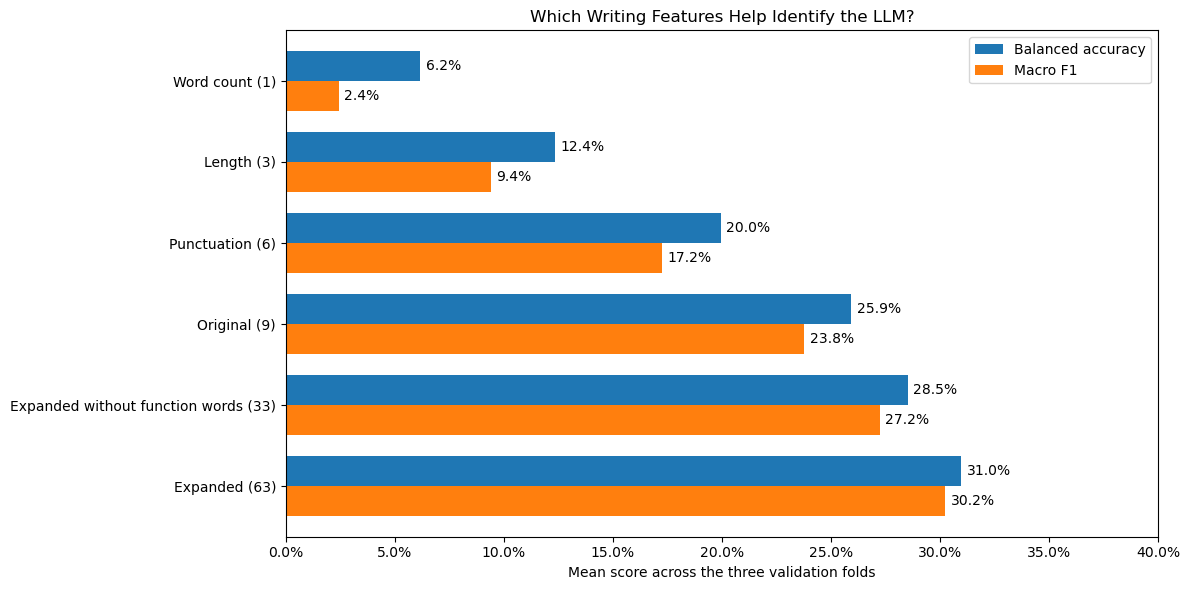

Expanded minus original: +5.1 percentage points in balanced accuracy and +6.5 in macro F1.
Adding function words: +2.5 percentage points in balanced accuracy and +3.0 in macro F1.
Expanded features had higher balanced accuracy in 3 of 3 folds.


In [ ]:
feature_plot = feature_mean_scores.rename(columns={"balanced_accuracy": "Balanced accuracy","macro_f1": "Macro F1",}).mul(100)

ax = feature_plot.plot.barh(figsize=(12, 6), width=0.75)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", padding=4)

ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_xlim(0,min(100, max(40, np.ceil(feature_plot.to_numpy().max() / 10) * 10)),
)
ax.set_xlabel("Mean score across the three validation folds")
ax.set_ylabel("")
ax.legend(loc="upper right")

plt.title("Which Writing Features Help Identify the LLM?")
plt.tight_layout()
plt.show()

feature_gain = (feature_mean_scores.loc["Expanded (63)"]- feature_mean_scores.loc["Original (9)"]).mul(100)
function_word_gain = (feature_mean_scores.loc["Expanded (63)"]- feature_mean_scores.loc["Expanded without function words (33)"]).mul(100)

feature_fold_scores = feature_comparison_results.pivot(
    index="fold",
    columns="features",
    values="balanced_accuracy",
)

improved_folds = (
    feature_fold_scores["Expanded (63)"]
    > feature_fold_scores["Original (9)"]
).sum()

print("Expanded minus original: "f"{feature_gain['balanced_accuracy']:+.1f} percentage points in balanced "f"accuracy and {feature_gain['macro_f1']:+.1f} in macro F1.")
print("Adding function words: "f"{function_word_gain['balanced_accuracy']:+.1f} percentage points in "f"balanced accuracy and {function_word_gain['macro_f1']:+.1f} in macro F1.")
print("Expanded features had higher balanced accuracy in "f"{improved_folds} of {len(folds)} folds.")